# StockSense - Round 1: Data Understanding, Preparation & EDA
**NovaMart Retail Pvt. Ltd. | IntelliData 2026**

Business question: *can we predict what will sell, spot products likely to go out of stock, and tell
store managers what to do before it happens?*

This notebook covers the audit of the five raw files, cleaning and integration into one master table
(grain: **one date x one store x one product**), EDA where every chart answers a business question,
and four hypothesis tests.

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings('ignore')
import pandas as pd, numpy as np
from IPython.display import Image, Markdown, display
pd.set_option('display.max_columns', 40); pd.set_option('display.width', 200)
FIG = ROOT / 'reports' / 'figures'

## 1. Audit the raw files
Data types, missing values, duplicates and obviously invalid values, before touching anything.

In [2]:
RAW = ROOT / 'data' / 'raw'
raw = {n: pd.read_csv(RAW / f'{n}.csv') for n in ['transactions','products','stores','inventory','external_factors']}
audit = pd.DataFrame({n: {'rows': len(d), 'columns': d.shape[1], 'missing cells': int(d.isna().sum().sum()),
                          'duplicate rows': int(d.duplicated().sum())} for n, d in raw.items()}).T
audit

,rows,columns,missing cells,duplicate rows
transactions,253614,11,1014,1827
products,47,9,2,0
stores,6,6,0,0
inventory,41490,9,60,120
external_factors,960,8,43,0


In [3]:
t = raw['transactions']
print('Duplicate transaction_id :', t.transaction_id.duplicated().sum())
print('Quantity <= 0            :', (t.quantity <= 0).sum())
print('Quantity > 100           :', (t.quantity > 100).sum())
print('Non-standard store IDs   :', (~t.store_id.astype(str).str.fullmatch(r'S\d{2}')).sum())
print('Non-ISO dates            :', (~t.date.astype(str).str.match(r'^\d{4}-\d{2}-\d{2}$')).sum())
print('\nRaw category labels:', sorted(raw['products'].category.unique()))
inv = raw['inventory']
print('\nInventory rows where closing != opening + received - sold:',
      int((inv.opening_stock + inv.received_qty - inv.sold_qty != inv.closing_stock).sum()))

Duplicate transaction_id : 2013
Quantity <= 0            : 377
Quantity > 100           : 40
Non-standard store IDs   : 2536
Non-ISO dates            : 2536

Raw category labels: ['BEVERAGES', 'Beverages', 'Beverages ', 'DAIRY', 'Dairy', 'Frozen', 'GROCERIES', 'Groceries', 'Household', 'Personal Care', 'SNACKS', 'Snacks', 'beverage', 'dairy', 'frozen', 'household', 'personal care', 'snack']

Inventory rows where closing != opening + received - sold: 472


## 2. Clean and integrate
All rules live in `src/data_cleaning.py` so the notebook and the pipeline can never disagree.

In [4]:
from src import data_cleaning
master = data_cleaning.run()

           table                                                     issue  count
        products Category spelling/case inconsistency (18 raw labels -> 7)     11
        products                                   Missing shelf_life_days      2
          stores                          City name whitespace/case issues      1
external_factors                                       Missing temperature     29
external_factors                                          Missing rainfall     14
    transactions             Duplicate rows (same transaction_id repeated)   2013
    transactions               Store IDs with lower-case / trailing spaces   2516
    transactions                          Non-ISO date format (dd-mm-yyyy)   2514
    transactions                           Payment mode case inconsistency   5031
    transactions                                Impossible quantity (<= 0)    375
    transactions              Extreme basket quantity (e.g. 150-400 units)     40
    transactions

### Data Quality Report
One row per issue: count, action taken and justification (also saved to `reports/data_quality_report.md`).

In [5]:
pd.read_csv(ROOT / 'reports' / 'data_quality_log.csv')

,table,issue,count,action,justification
0,products,Category spelling/case inconsistency (18 raw l...,11,Mapped to 7 canonical categories,Groupings like 'beverage' vs 'BEVERAGES' would...
1,products,Missing shelf_life_days,2,Imputed with sub-category (else category) median,Shelf life is a stable product attribute; sibl...
2,stores,City name whitespace/case issues,1,Trimmed and title-cased,City is the join key to external_factors.csv.
3,external_factors,Missing temperature,29,Linear interpolation within city,Temperature changes smoothly day to day; neigh...
4,external_factors,Missing rainfall,14,Filled with 0 mm,Most days are dry (median = 0); a missing read...
5,transactions,Duplicate rows (same transaction_id repeated),2013,"Removed, kept first occurrence",A repeated transaction_id is a double-posting;...
6,transactions,Store IDs with lower-case / trailing spaces,2516,Trimmed and upper-cased,Otherwise 's01 ' and 'S01' become two stores.
7,transactions,Non-ISO date format (dd-mm-yyyy),2514,Parsed both formats into one datetime,Mixed formats silently mis-sort time series.
8,transactions,Payment mode case inconsistency,5031,Standardised to UPI/Card/Cash,Needed for clean payment-mix reporting.
9,transactions,Impossible quantity (<= 0),375,"Removed from demand, logged",Negative sale quantities are returns/keying er...


In [6]:
print(master.shape)
print('Unique grain check:', not master.duplicated(['date','store_id','product_id']).any())
master.head()

(41370, 41)
Unique grain check: True


,date,store_id,product_id,opening_stock,received_qty,sold_qty,closing_stock,reorder_level,lead_time_days,inventory_mismatch_flag,recorded_closing_stock,units_sold,revenue,n_transactions,avg_selling_price,discount_pct,promotion_flag,category,sub_category,brand,...,mrp,cost_price,shelf_life_days,supplier_id,margin_pct,city,store_type,floor_area_sqft,avg_daily_customers,region,temp_c,rain_mm,holiday,festival,weekend,local_event,pos_vs_inventory_gap,stockout_flag,inventory_value,cogs
0,2026-04-01,S01,P101,216,0,18,198,80.0,1,0,198,18.0,1080.0,8.0,60.0,0.0,0,Dairy,Milk,Aavin,...,60,52,3.0,SUP01,13.333333,Coimbatore,Supermarket,8500,1250,West,31.3,0.0,0,0,0,0,0.0,0,10296,936.0
1,2026-04-01,S01,P102,131,0,13,118,49.0,1,0,118,13.0,520.0,8.0,40.0,0.0,0,Dairy,Curd,Aavin,...,40,31,5.0,SUP01,22.500000,Coimbatore,Supermarket,8500,1250,West,31.3,0.0,0,0,0,0,0.0,0,3658,403.0
2,2026-04-01,S01,P103,65,0,2,63,35.0,2,0,63,2.0,190.0,1.0,95.0,0.0,0,Dairy,Paneer,Milky Mist,...,95,72,10.0,SUP02,24.210526,Coimbatore,Supermarket,8500,1250,West,31.3,0.0,0,0,0,0,0.0,0,4536,144.0
3,2026-04-01,S01,P104,56,0,19,37,31.0,2,0,37,19.0,1102.0,10.0,58.0,0.0,0,Dairy,Butter,Amul,...,58,47,180.0,SUP02,18.965517,Coimbatore,Supermarket,8500,1250,West,31.3,0.0,0,0,0,0,0.0,0,1739,893.0
4,2026-04-01,S01,P105,23,0,2,21,13.0,2,0,21,2.0,290.0,2.0,145.0,0.0,0,Dairy,Cheese,Amul,...,145,112,180.0,SUP02,22.758621,Coimbatore,Supermarket,8500,1250,West,31.3,0.0,0,0,0,0,0.0,0,2352,224.0


**Stock-out definition (operational):** a store-product day is a stock-out day when the closing stock
is zero, meaning the shelf was empty at the end of trading. For modelling, the target is whether
*any* day in the next 7 days is a stock-out day.

## 3. Exploratory Data Analysis
Each figure is produced by `src/eda.py`.

In [7]:
from src import eda
summary = eda.run()

{
 "revenue_total": 36670554.0,
 "units_total": 470762,
 "revenue_last_28d": 6869933.0,
 "revenue_growth_28d": 0.0011,
 "stockout_rate": 0.0573,
 "inventory_turnover_annualised": 66.07,
 "inventory_value_latest": 959864.0,
 "days_of_inventory_median": 4.6,
 "estimated_lost_sales": 1560469.0,
 "estimated_lost_units": 20142,
 "date_min": "2026-04-01",
 "date_max": "2026-08-31"
}
promo lift 0.3166 weekend 0.1456
growth {'S01': 0.1404, 'S02': 0.3048, 'S03': -0.076, 'S04': 0.0971, 'S05': 0.1783, 'S06': -0.005}


### Q1. Which categories generate the most revenue?

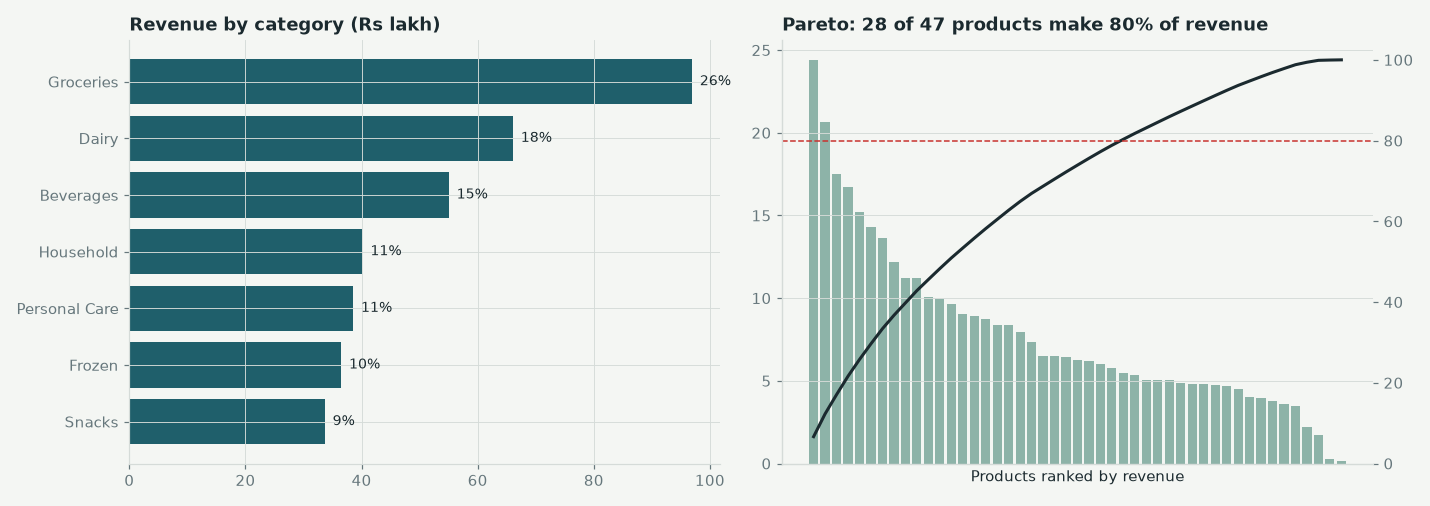

Products making 80% of revenue: 28


In [8]:
display(Image(FIG / '01_category_revenue_pareto.png'))
print('Products making 80% of revenue:', summary['pareto_products_for_80pct'])

Dairy and Groceries dominate revenue and are also the fastest movers. A small head of products
drives most of the revenue (Pareto), so forecast accuracy on those items matters most.

### Q2. Which stores are growing or declining?

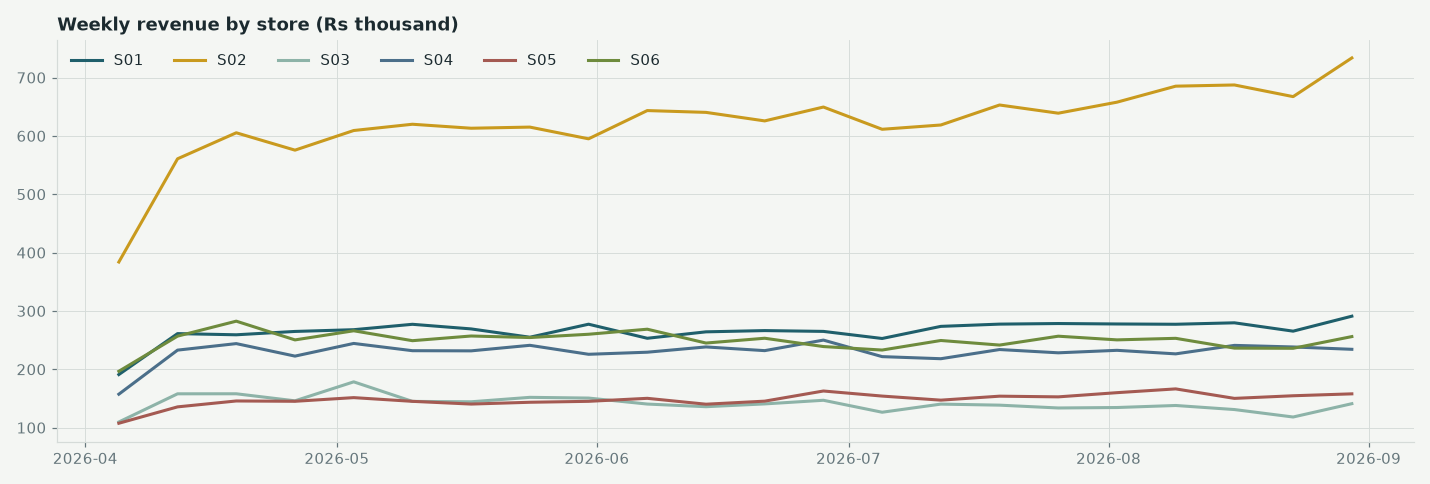

S03     -7.6%
S06     -0.5%
S04     +9.7%
S01    +14.0%
S05    +17.8%
S02    +30.5%
dtype: str

In [9]:
display(Image(FIG / '02_store_weekly_trend.png'))
pd.Series(summary['store_growth_first4_vs_last4_weeks']).sort_values().map('{:+.1%}'.format)

S02 Chennai and S05 Tiruppur are growing fast, while S03 Madurai is declining. Growing stores are
where fixed reorder levels break first.

### Q3. Do promotions increase units sold?

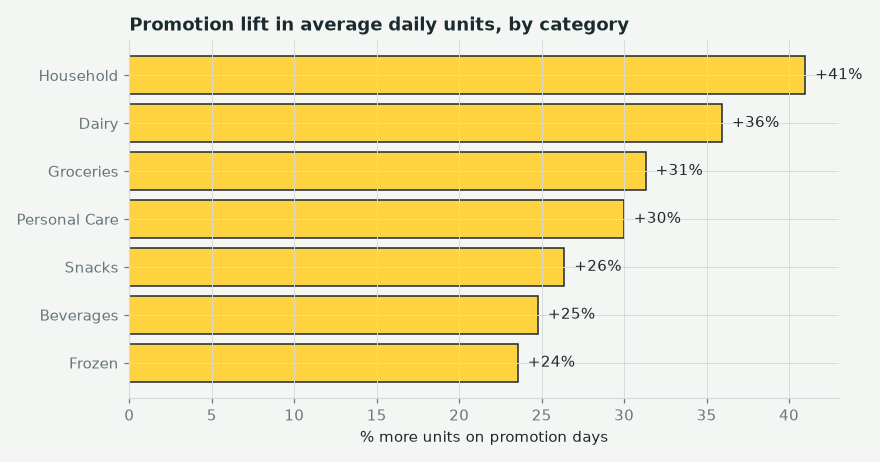

In [10]:
display(Image(FIG / '03_promotion_lift.png'))

### Q4. How does weekend behaviour differ?

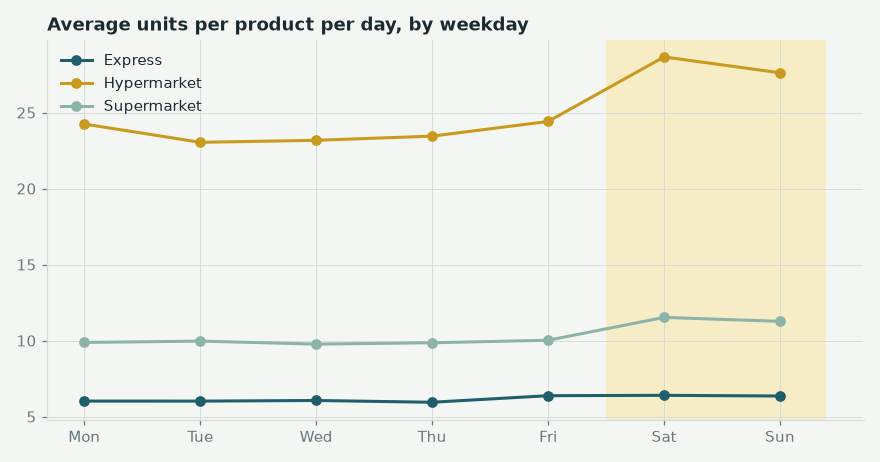

Weekend uplift: +14.6%


In [11]:
display(Image(FIG / '04_weekday_weekend.png'))
print(f"Weekend uplift: {summary['weekend_uplift']:+.1%}")

### Q5. Which products are volatile?

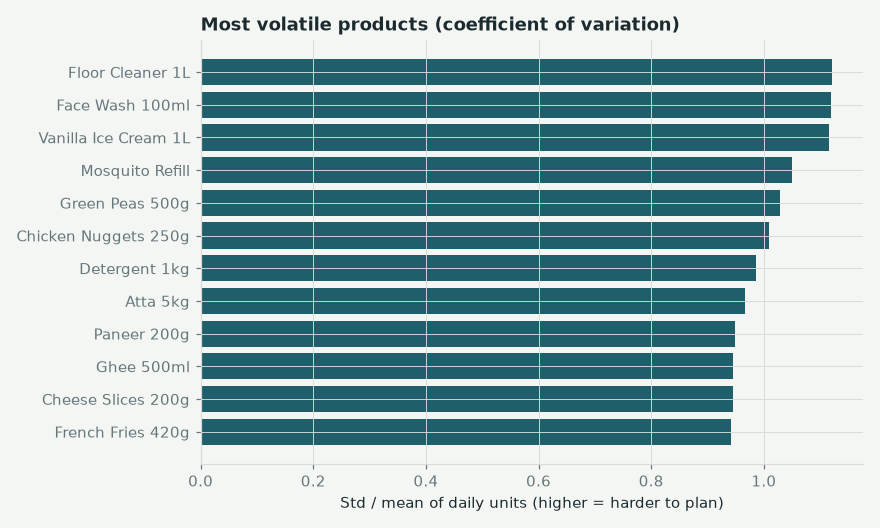

In [12]:
display(Image(FIG / '05_volatility_cv.png'))

High coefficient-of-variation items (ice cream, cold drinks, low-volume personal care) need
proportionally more safety stock. That is why the reorder logic uses each item's own demand
standard deviation.

### Q6. Which stores repeatedly stock out?

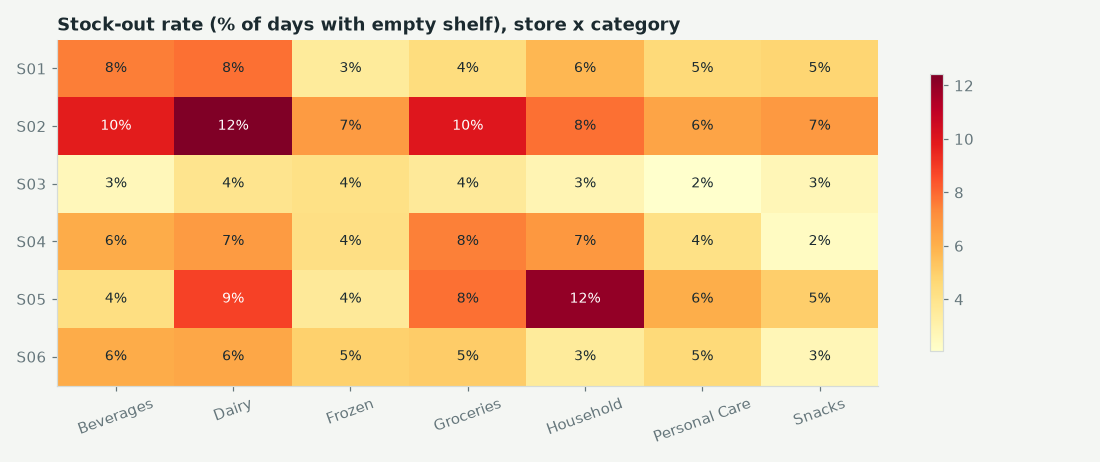

In [13]:
display(Image(FIG / '06_stockout_heatmap.png'))

S02 stocks out most across almost every category. Combined with Q2, this is the headline finding:
**the fastest-growing store has the emptiest shelves**, because its replenishment rules were never
re-sized.

### Q7. Does heat drive beverage and frozen demand?

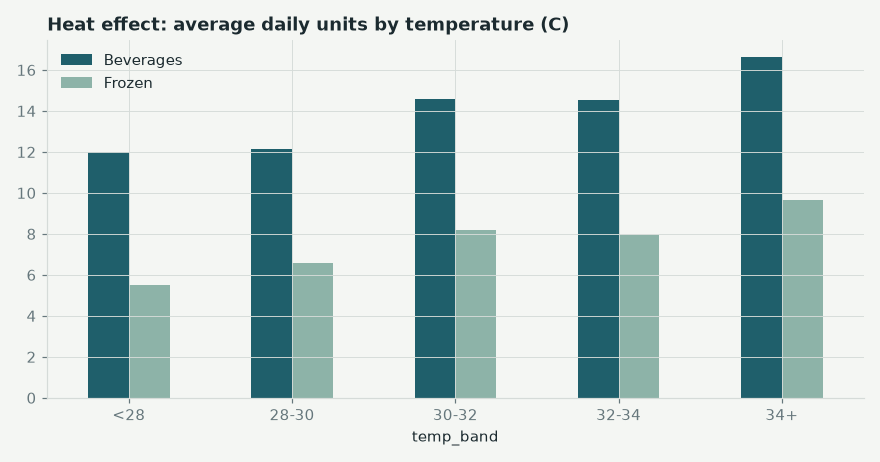

In [14]:
display(Image(FIG / '07_temperature_effect.png'))

### Headline KPIs

In [15]:
pd.Series(summary['kpi'])

revenue_total                    36670554.0
units_total                          470762
revenue_last_28d                  6869933.0
revenue_growth_28d                   0.0011
stockout_rate                        0.0573
inventory_turnover_annualised         66.07
inventory_value_latest             959864.0
days_of_inventory_median                4.6
estimated_lost_sales              1560469.0
estimated_lost_units                  20142
date_min                         2026-04-01
date_max                         2026-08-31
dtype: object

## 4. Statistical reasoning
Business question, H0, H1, test, p-value and business interpretation for each.

In [16]:
from src import stats_tests
res = stats_tests.run()
pd.DataFrame(res)[['question','test','statistic','p_value','significant','effect']]

Do promotions significantly increase sales?               p=6.08e-42  Median lift per store-product: +30.8% (n = 264 pairs)
Does mean demand differ across store types?               p=5.74e-164  Mean daily units per store: {'Express': 278.0, 'Hypermarket': 1125.0, 'Supermarket': 465.0}
Is stock-out frequency associated with promotion status   p=2.67e-05  Stock-out rate: 7.2% on promotion days vs 5.6% otherwise (Cramer's V = 0.021)
Is weekend demand higher than weekday demand?             p=5.92e-19  Average weekend uplift: +14.3%


,question,test,statistic,p_value,significant,effect
0,Do promotions significantly increase sales?,"Wilcoxon signed-rank (one-sided), paired by st...",34050.0000,6.080638e-42,True,Median lift per store-product: +30.8% (n = 264...
1,Does mean demand differ across store types?,Kruskal-Wallis H test (ANOVA checked as well),751.7539,5.737409e-164,True,"Mean daily units per store: {'Express': 278.0,..."
2,Is stock-out frequency associated with promoti...,Chi-square test of independence (2 x 2),17.6366,2.673907e-05,True,Stock-out rate: 7.2% on promotion days vs 5.6%...
3,Is weekend demand higher than weekday demand?,Paired t-test (one-sided) on store x product m...,9.4719,5.920316e-19,True,Average weekend uplift: +14.3%


In [17]:
for r in res:
    display(Markdown(f"**{r['question']}**  \nH0: {r['h0']}  \nH1: {r['h1']}  \n"
                     f"Test: {r['test']} - {r['why_test']}  \np = {r['p_value']:.3g}  \n"
                     f"*Interpretation:* {r['interpretation']}"))

**Do promotions significantly increase sales?**  
H0: Median daily units are the same on promotion and non-promotion days.  
H1: Median daily units are higher on promotion days.  
Test: Wilcoxon signed-rank (one-sided), paired by store x product - Daily units are skewed counts, so a non-parametric paired test is safer than a t-test; pairing controls for product size.  
p = 6.08e-42  
*Interpretation:* Promotions lift units by about 31% for the typical item. Promotion calendars must feed the replenishment plan, otherwise promotions create their own stock-outs.

**Does mean demand differ across store types?**  
H0: Daily store demand has the same distribution for Express, Supermarket and Hypermarket.  
H1: At least one store type differs.  
Test: Kruskal-Wallis H test (ANOVA checked as well) - Levene's test p = 2.6e-59 shows unequal variances, which breaks an ANOVA assumption; Kruskal-Wallis does not need equal variances.  
p = 5.74e-164  
*Interpretation:* Store formats behave very differently, so one national reorder rule is wrong. Store type is kept as a model feature and safety stock is set per store.

**Is stock-out frequency associated with promotion status?**  
H0: Stock-out occurrence is independent of whether a promotion is running.  
H1: Stock-out occurrence depends on promotion status.  
Test: Chi-square test of independence (2 x 2) - Both variables are binary categories; expected counts are all well above 5.  
p = 2.67e-05  
*Interpretation:* Promotion days are more likely to end with an empty shelf. The association is statistically clear but small on its own (low Cramer's V), which tells us promotions matter mostly in combination with low stock cover - exactly what a multivariate stock-out model captures. The promotion flag is kept as a model input.

**Is weekend demand higher than weekday demand?**  
H0: Mean daily units on weekends equal weekday units for the same item.  
H1: Weekend units are higher.  
Test: Paired t-test (one-sided) on store x product means - Each pair is an average of many days, so means are close to normal (CLT); pairing removes product size.  
p = 5.92e-19  
*Interpretation:* Orders placed on Thursday should cover a heavier weekend; the 7-day forecast includes day-of-week features for this.